In [17]:
#Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import pickle

In [15]:
#Load Dataset
df = pd.read_csv("HR_Job_Placement_Dataset.csv")

print(df.shape)

df.head()

(51500, 26)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [19]:
#Basic Understanding

df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  str    
 14  r

age_years                       0
gender                          0
ssc_percentage               2581
hsc_percentage               2065
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8466
relevant_experience          8426
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               6131
competition_level               0
bond_requirement                0
notice_period_days           1582
layoff_history               8467
employment_gap_months        1097
relocation_willingness       8475
status                          0
dtype: int64

In [20]:
#Data Cleaning
num_cols = df.select_dtypes(include='number').columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())

In [21]:
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

cat_cols = df.select_dtypes(include=['object', 'string']).columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [22]:
duplicates_removed = df.duplicated().sum()

df.drop_duplicates(inplace=True)

print("Duplicate rows removed:", duplicates_removed)

Duplicate rows removed: 1376


In [13]:
for col in cat_cols:
    df[col] = df[col].str.strip()
    df[col] = df[col].str.title()

In [24]:
#Feature Engineering

def experience_category(x):

    if x < 2:
        return "Fresher"

    elif x < 5:
        return "Junior"

    else:
        return "Senior"

df["Experience_Category"] = \
df["years_of_experience"].apply(
experience_category
)

In [25]:
academic_score = (
df["ssc_percentage"] +
df["hsc_percentage"] +
df["degree_percentage"]
) / 3

def academic_band(x):

    if x < 60:
        return "Low"

    elif x < 75:
        return "Medium"

    else:
        return "High"

df["Academic_Band"] = \
academic_score.apply(
academic_band
)

In [26]:
def skill_level(x):

    if x < 50:
        return "Low"

    elif x < 75:
        return "Medium"

    else:
        return "High"

df["Skill_Level"] = \
df["skills_match_percentage"].apply(
skill_level
)

In [27]:
def interview_category(x):

    if x < 60:
        return "Poor"

    elif x < 75:
        return "Average"

    else:
        return "Excellent"

df["Interview_Category"] = \
df["technical_score"].apply(
interview_category
)

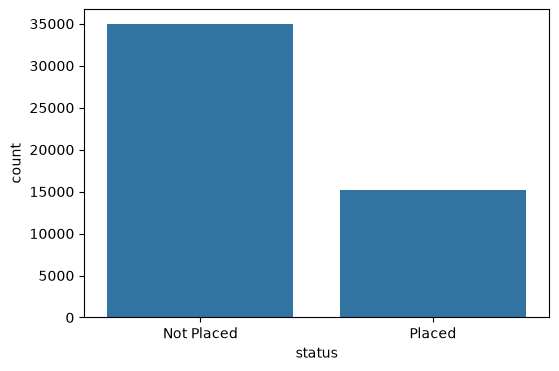

In [28]:
#EDA
plt.figure(figsize=(6,4))

sns.countplot(x='status',data=df)

plt.show()

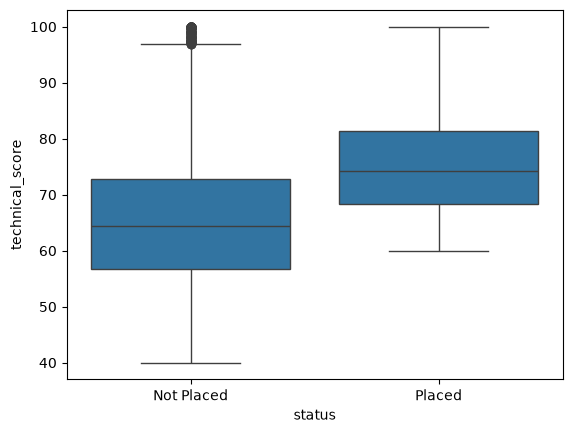

In [29]:
sns.boxplot(
x='status',
y='technical_score',
data=df
)

plt.show()

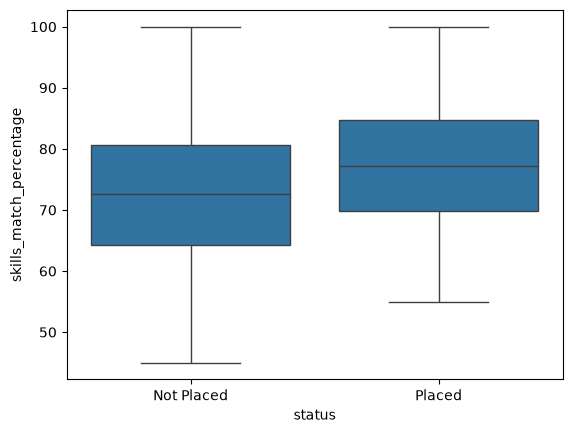

In [30]:
sns.boxplot(
x='status',
y='skills_match_percentage',
data=df
)

plt.show()

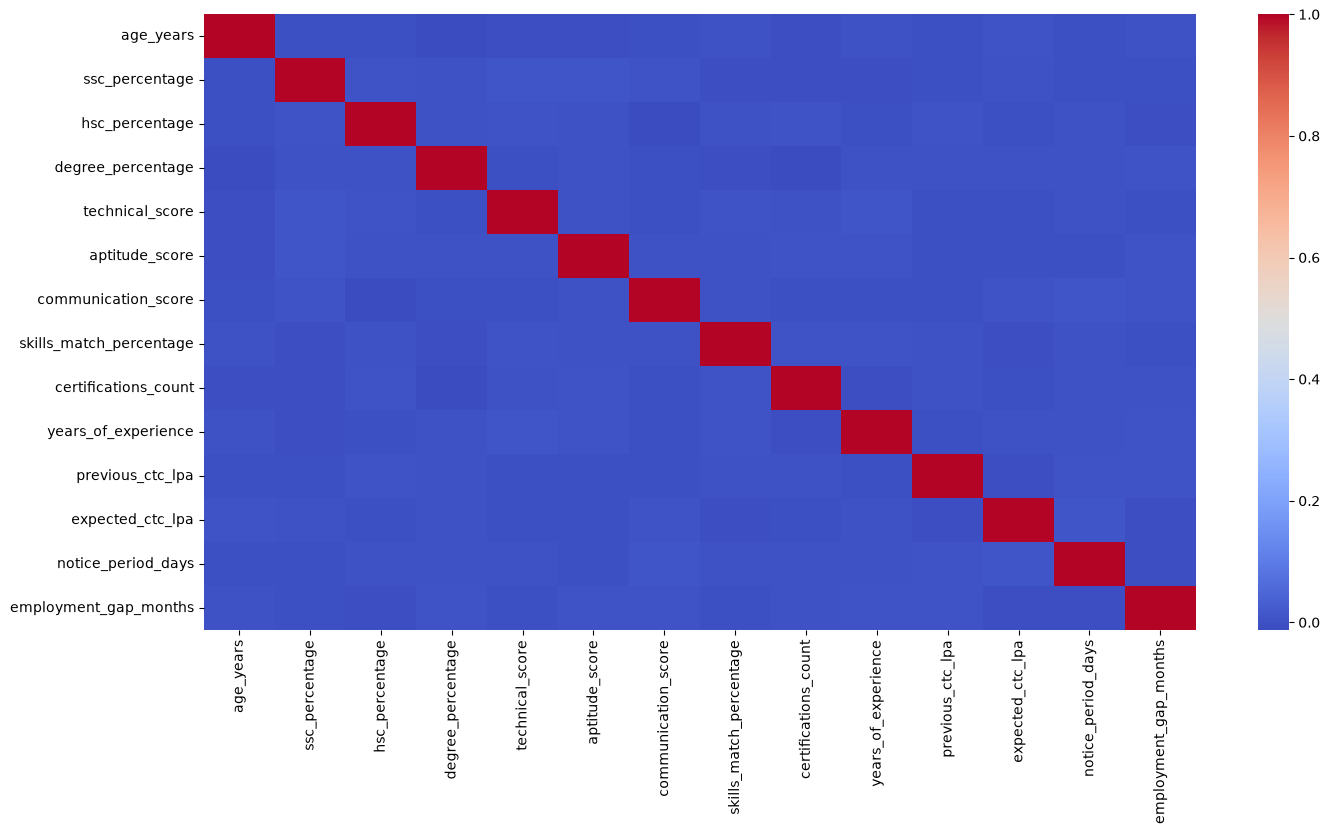

In [31]:
plt.figure(figsize=(16,8))

sns.heatmap(
df.corr(numeric_only=True),
cmap='coolwarm'
)

plt.show()

In [46]:
#Machine Learning

selected_features = [

    "age_years",
    "years_of_experience",
    "technical_score",
    "aptitude_score",
    "communication_score",
    "skills_match_percentage"

]

X = df[selected_features]

y = df["status"]

In [47]:
X_train, X_test, y_train, y_test = \
train_test_split(
X,
y,
test_size=0.2,
random_state=42,
stratify=y
)

In [48]:
cat_cols = X_train.select_dtypes(
include='object'
).columns

num_cols = X_train.select_dtypes(
include=np.number
).columns

In [49]:
preprocessor = ColumnTransformer(

transformers=[

(
"num",
Pipeline([
("imputer",
SimpleImputer(strategy="median")),

("scaler",
StandardScaler())
]),
num_cols
),

(
"cat",
Pipeline([
("imputer",
SimpleImputer(strategy="most_frequent")),

("encoder",
OneHotEncoder(
handle_unknown="ignore"
))
]),
cat_cols
)

]
)

In [50]:
#Model Comparison
##Logistic Regression
lr_model = Pipeline([
("preprocessor",preprocessor),
("model",LogisticRegression())
])

lr_model.fit(X_train,y_train)

lr_pred = lr_model.predict(X_test)

lr_acc = accuracy_score(
y_test,
lr_pred
)

print(lr_acc)

0.7952119700748129


In [51]:
#Decision Tree

dt_model = Pipeline([
("preprocessor",preprocessor),
("model",DecisionTreeClassifier())
])

dt_model.fit(X_train,y_train)

dt_pred = dt_model.predict(X_test)

dt_acc = accuracy_score(
y_test,
dt_pred
)

print(dt_acc)

0.758503740648379


In [52]:
#Random Forest

rf_model = Pipeline([
("preprocessor",preprocessor),
("model",RandomForestClassifier(
n_estimators=200,
random_state=42
))
])

rf_model.fit(
X_train,
y_train
)

rf_pred = rf_model.predict(
X_test
)

rf_acc = accuracy_score(
y_test,
rf_pred
)

print(rf_acc)

0.8149625935162095


In [53]:
print("Random Forest Accuracy")

print(
accuracy_score(
y_test,
rf_pred
)
)

print(
classification_report(
y_test,
rf_pred
)
)

Random Forest Accuracy
0.8149625935162095
              precision    recall  f1-score   support

  Not Placed       0.85      0.89      0.87      6990
      Placed       0.72      0.64      0.68      3035

    accuracy                           0.81     10025
   macro avg       0.78      0.77      0.77     10025
weighted avg       0.81      0.81      0.81     10025



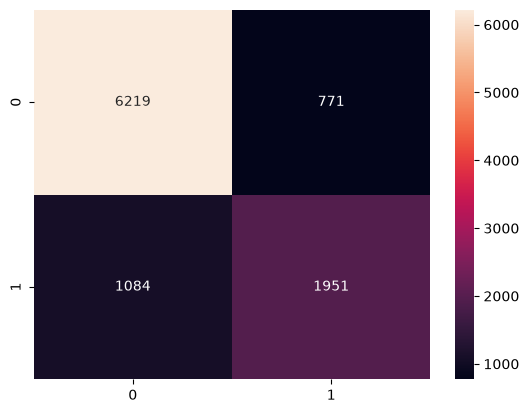

In [54]:
cm = confusion_matrix(
y_test,
rf_pred
)

sns.heatmap(
cm,
annot=True,
fmt="d"
)

plt.show()

In [55]:
#Feature Importance

rf = rf_model.named_steps["model"]

feature_names = (
rf_model.named_steps[
"preprocessor"
].get_feature_names_out()
)

importance = pd.DataFrame({

"Feature":feature_names,
"Importance":rf.feature_importances_

})

importance = importance.sort_values(
"Importance",
ascending=False
)

print(
importance.head(20)
)

                        Feature  Importance
2          num__technical_score    0.339404
5  num__skills_match_percentage    0.184060
4      num__communication_score    0.143377
1      num__years_of_experience    0.136092
3           num__aptitude_score    0.128811
0                num__age_years    0.068256


In [56]:
#Save Model

pickle.dump(
rf_model,
open(
"job_acceptance_model.pkl",
"wb"
)
)